# ET0737 Mini Project — Customer Churn Prediction
**Task type:** Classification | **Dataset:** IBM Telco Customer Churn

Source: https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv

## 1. Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/Telco-Customer-Churn.csv')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Exploratory Data Analysis
Distributions, missing values, outliers, correlations, class balance.

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

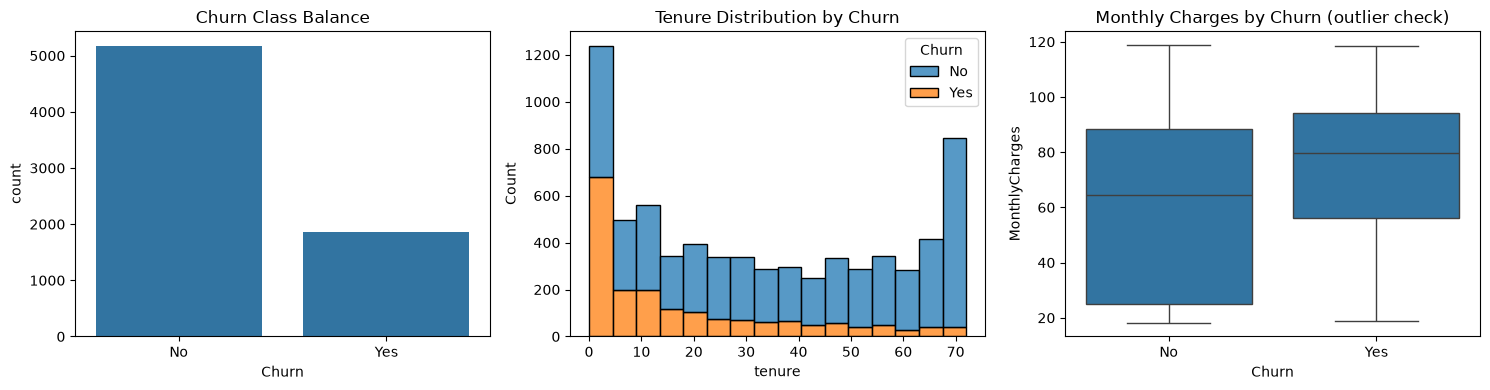

In [2]:
df.info()

print("\nMissing (NaN) values per column:\n", df.isna().sum()[df.isna().sum() > 0])

# NaN-check alone misses blank/whitespace strings in object columns (e.g. TotalCharges) -
# pandas reads these as empty strings, not NaN, so they need an explicit check here.
blank_counts = df.select_dtypes(include='str').apply(lambda col: col.str.strip().eq('').sum())
print("\nBlank-string values per object column:\n", blank_counts[blank_counts > 0])

print("\nChurn class balance:")
print(df['Churn'].value_counts(normalize=True))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x='Churn', ax=axes[0])
axes[0].set_title('Churn Class Balance')

sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', ax=axes[1])
axes[1].set_title('Tenure Distribution by Churn')

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[2])
axes[2].set_title('Monthly Charges by Churn (outlier check)')

plt.tight_layout()
plt.show()

## 3. Data Cleaning
Handle missing values (median imputation) and outliers. Note: `TotalCharges` is loaded as object due to blank strings for tenure=0 customers — needs conversion.

In [3]:
# customerID is a unique identifier, not a predictive feature
df = df.drop(columns=['customerID'])

# TotalCharges loaded as object due to blank strings for tenure=0 (new) customers -> convert to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(f"Missing TotalCharges after numeric conversion: {df['TotalCharges'].isna().sum()}")

# Median imputation for the resulting missing values (robust to skew/outliers vs. mean)
df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())

# Outlier scan on numeric columns
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
df[numeric_cols].describe()

Missing TotalCharges after numeric conversion: 11


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


## 4. Feature Transformation & Encoding
Feature scaling (StandardScaler/MinMaxScaler) and One-Hot Encoding for categoricals.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Encode target as binary
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# SeniorCitizen is already binary numeric (0/1); treat alongside the other numeric features
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
categorical_features = [c for c in df.columns if c not in numeric_features + ['Churn']]

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

# Define (but do NOT fit yet) — fitting happens after the split to avoid data leakage
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features),
])

Numeric features (4): ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
Categorical features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 5. Train / Validation / Test Split
Split BEFORE fitting any scaler/encoder to prevent data leakage.

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']

# 60/20/20 train/val/test, stratified to preserve the ~26% churn class balance
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42
)

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

# Fit the preprocessor ONLY on training data, then transform val/test — prevents data leakage
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print(f"Processed feature count after encoding: {X_train_processed.shape[1]}")

Train: (4225, 19), Val: (1409, 19), Test: (1409, 19)
Processed feature count after encoding: 30


## 6. Model Training
Baseline (Logistic Regression) + advanced models (Decision Tree, Random Forest, SVM, MLP).

## 7. Hyperparameter Tuning
GridSearchCV / RandomizedSearchCV.

## 8. Evaluation & Overfitting Check
Accuracy, Precision, Recall, F1, Confusion Matrix. Train vs validation comparison.

## 9. Model Comparison Table

## 10. Business Insights & Conclusions